# Test Set: 2D Diffusion Inversion with an Implicit Neural Representation (INR)


In [1]:
from pathlib import Path
from collections import defaultdict
from functools import partial
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from tqdm.auto import tqdm
from IPython.display import display
from diffusers import UNet2DConditionModel, MultiControlNetModel
from diffusers.utils.torch_utils import randn_tensor

from myddim_schedule import DDIMScheduler
from utils import wavelet_forward, calc_metrics
from inference_utils import get_impedance_cmap
from paper_plotting import section_figure_size, paper_section, paper_colorbar as add_colorbar
from inversion_utils import (
    wavelet_fitting, make_background_filter, initial_fn, forward_wavelet_fn,
)

from models.inr import create_coords, create_model


## 1. Device, Model, and Schedulers


In [2]:
ROOT = Path.cwd().resolve()
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
path = ROOT / "weights" / "checkpoint-22608"

torch.set_num_threads(8)
if device.type == "cuda":
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.allow_tf32 = True
    torch.backends.cuda.matmul.allow_tf32 = False

unet = UNet2DConditionModel.from_pretrained(path, subfolder="unet").to(device)
controlnet = MultiControlNetModel.from_pretrained(str(path / "controlnet/controlnet")).to(device)
unet.eval().requires_grad_(False)
controlnet.eval().requires_grad_(False)
scheduler = DDIMScheduler.from_pretrained(path, subfolder="scheduler")
scheduler2 = DDIMScheduler.from_pretrained(path, subfolder="scheduler")
if scheduler.config.prediction_type != "v_prediction" or scheduler.config.num_train_timesteps != 1500:
    raise ValueError("The checkpoint prediction type or number of training timesteps does not match the settings used in the paper.")
print("Device:", device)


The config attributes {'add_attention': True, 'attn_norm_num_groups': None, 'downsample_type': 'conv', 'num_train_timesteps': None, 'upsample_type': 'conv'} were passed to UNet2DConditionModel, but are not expected and will be ignored. Please verify your config.json configuration file.


Device: cuda:0


## 2. Select Input Data


In [3]:
data_dir = ROOT / "data" / "testset" / "section_main_vol00983_slice_363"
output_dir = ROOT / "results" / "testset_inr" / data_dir.name
output_dir.mkdir(parents=True, exist_ok=True)

metadata = json.loads((data_dir / "section_metadata.json").read_text(encoding="utf-8"))
print("Input:", data_dir)
print("Output:", output_dir)


Input: /wzg3/home/hanlong/MyProject/2DGeoDiffInv/data/testset/section_main_vol00983_slice_363
Output: /wzg3/home/hanlong/MyProject/2DGeoDiffInv/results/testset_inr/section_main_vol00983_slice_363


## 3. Impedance Section and Observed Seismic Data


In [4]:
imp_min, imp_max = float(metadata["imp_min"]), float(metadata["imp_max"])
raw_image_denorm = torch.from_numpy(
    np.load(data_dir / "clean_section.npy", allow_pickle=False)).float().unsqueeze(0).to(device)
raw_image = (raw_image_denorm - imp_min) / (imp_max - imp_min)
seis_slice = torch.from_numpy(
    np.load(data_dir / "seis_slice.npy", allow_pickle=False)).float()[None, None].to(device)
if raw_image.ndim != 3 or tuple(raw_image.shape[-2:]) != tuple(seis_slice.shape[-2:]):
    raise ValueError("Impedance and seismic data must be 2D sections with matching dimensions.")
seis_min, seis_max = seis_slice.min(), seis_slice.max()
seis_amplitude = float(seis_slice.abs().max())
if seis_amplitude <= 0:
    raise ValueError("The observed seismic amplitudes must not all be zero.")
seis = (seis_slice / seis_amplitude * 0.5 + 0.5).squeeze(0)

f0 = float(metadata.get("f0", 80.0))
dt = float(metadata.get("dt", metadata.get("seismic_generation", {}).get("dt", 0.0005)))
cmap = get_impedance_cmap("testset")
cmap2 = plt.get_cmap("seismic")
# Use the article color limits for the main profile; other profiles use their full impedance range by default.
if metadata.get("group") == "main_text_profile":
    plot_min, plot_max = imp_min * 1.4, imp_max * 0.9
else:
    plot_min, plot_max = imp_min, imp_max
aspect = 1
print("Shape:", tuple(raw_image.shape[-2:]), "| f0:", f0, "| dt:", dt)

# Evaluate with the true-profile range; physical normalization still uses imp_min/imp_max above.
metric_data_range = float(raw_image_denorm.max() - raw_image_denorm.min())

# The following settings only format the article figures; they do not affect normalization, forward modeling, or metrics.
plot_options = dict(dataset="testset_regularization", wells=metadata.get("well_starts", ()),
                    well_width=int(metadata.get("well_width", 3)), dt=dt)


Shape: (512, 512) | f0: 80.0 | dt: 0.0005


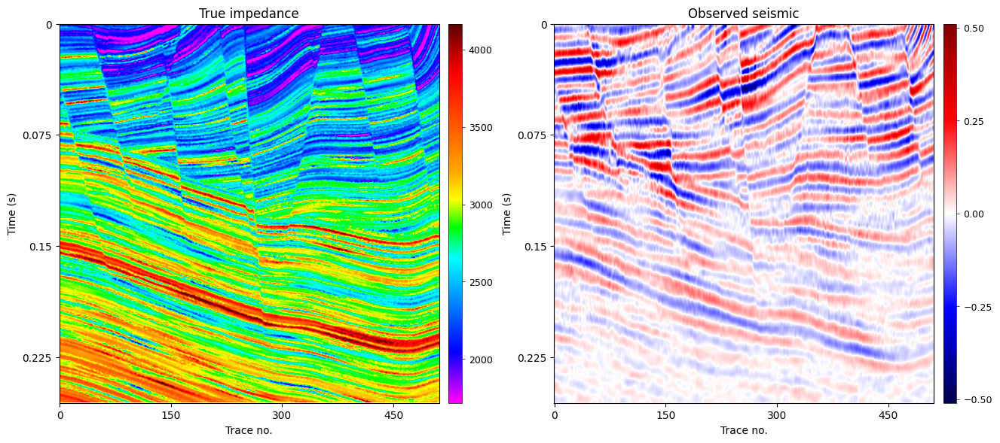

In [5]:
plt.figure(figsize=section_figure_size(raw_image.shape[-2:], dataset=plot_options["dataset"]))
plt.subplot(121)
plt.imshow(raw_image_denorm[0].cpu().T, cmap=cmap, vmin=plot_min, vmax=plot_max, aspect=aspect)
paper_section(plt.gca(), plt.gci(), impedance=True,
              show_wells=False, **plot_options)
plt.title("True impedance")
add_colorbar(plt.gcf(), plt.gci(), plt.gca())
plt.subplot(122)
plt.imshow(seis_slice[0, 0].cpu().T, cmap=cmap2, vmin=-seis_amplitude,
           vmax=seis_amplitude, aspect=aspect)
paper_section(plt.gca(), plt.gci(), impedance=False,
              show_wells=True, **plot_options)
plt.title("Observed seismic")
add_colorbar(plt.gcf(), plt.gci(), plt.gca())
plt.tight_layout()
plt.show()


## 4. Well Logs and Masks


Well starts: [30, 400]


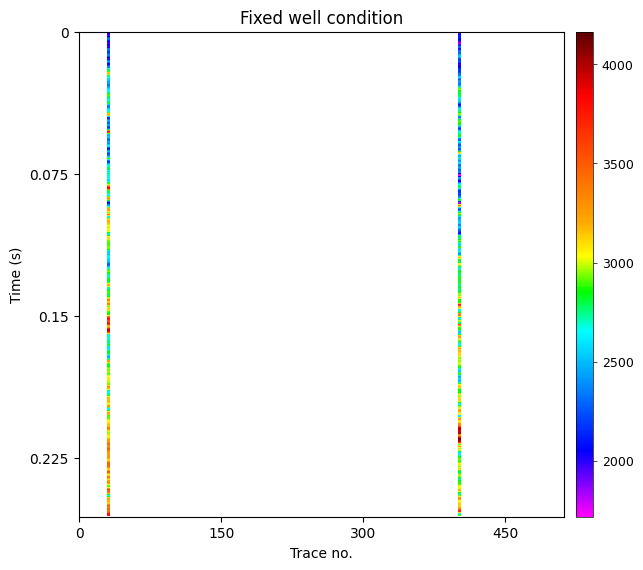

In [6]:
data_well_slice = torch.from_numpy(
    np.load(data_dir / "well_image.npy", allow_pickle=False)).float().unsqueeze(0).to(device)
mask_well_slice = torch.from_numpy(
    np.load(data_dir / "well_mask.npy", allow_pickle=False)).float().unsqueeze(0).to(device)
if data_well_slice.shape != raw_image.shape or mask_well_slice.shape != raw_image.shape:
    raise ValueError("Well logs, masks, and impedance must have matching dimensions.")
if mask_well_slice.sum() <= 0:
    raise ValueError("Wavelet estimation requires at least one valid well-log segment.")
if (data_well_slice * (1 - mask_well_slice)).any():
    raise ValueError("Well-log conditions must be zero outside the mask.")
well_images = data_well_slice.unsqueeze(0)
mask = mask_well_slice.unsqueeze(0)

columns = torch.where(mask[0, 0].any(dim=-1))[0].cpu().numpy()
dot = columns[np.r_[True, np.diff(columns) > 1]].tolist()
print("Well starts:", dot)
well_images_denorm = (well_images * 0.5 + 0.5) * (imp_max - imp_min) + imp_min
# Well overlays come from the actual input logs and masks and are used only for display.
plot_options.update(wells=dot,
                    well_values=well_images_denorm[0, 0].detach().cpu().numpy(),
                    well_mask=mask[0, 0].detach().cpu().numpy())
shown_wells = np.ma.masked_where(mask[0, 0].cpu().numpy().T == 0,
                                well_images_denorm[0, 0].cpu().numpy().T)
plt.figure(figsize=section_figure_size(raw_image.shape[-2:], cols=1, dataset=plot_options["dataset"]))
plt.imshow(shown_wells, cmap=cmap, vmin=plot_min, vmax=plot_max, aspect=aspect)
paper_section(plt.gca(), plt.gci(), impedance=True,
              show_wells=False, **plot_options)
plt.title("Fixed well condition")
add_colorbar(plt.gcf(), plt.gci(), plt.gca())
plt.tight_layout()
plt.show()


## 5. Initial Low-Frequency Model


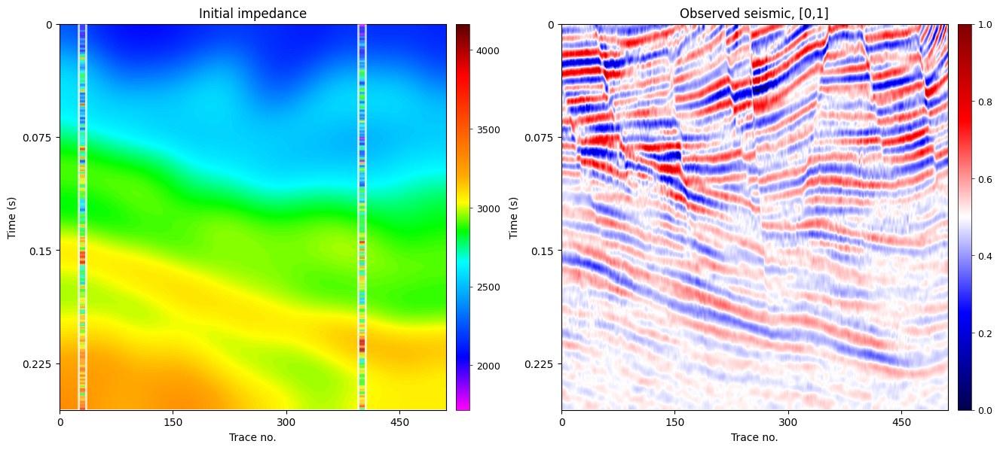

In [7]:
ks = int(metadata["initial_model_kernel"])
smoothed = torch.from_numpy(
    np.load(data_dir / "initial_model.npy", allow_pickle=False)).float().unsqueeze(0).to(device)
if smoothed.shape != raw_image.shape:
    raise ValueError("The initial model and impedance must have matching dimensions.")
if metadata.get("initial_model_scale") != "normalized_0_1":
    smoothed = (smoothed - imp_min) / (imp_max - imp_min)
smoothed_denorm = smoothed * (imp_max - imp_min) + imp_min

plt.figure(figsize=section_figure_size(raw_image.shape[-2:], dataset=plot_options["dataset"]))
plt.subplot(121)
plt.imshow(smoothed_denorm[0].cpu().T, cmap=cmap, vmin=plot_min, vmax=plot_max, aspect=aspect)
paper_section(plt.gca(), plt.gci(), impedance=True,
              show_wells=True, **plot_options)
plt.title("Initial impedance")
add_colorbar(plt.gcf(), plt.gci(), plt.gca())
plt.subplot(122)
plt.imshow(seis[0].cpu().T, cmap=cmap2, vmin=0, vmax=1, aspect=aspect)
paper_section(plt.gca(), plt.gci(), impedance=False,
              show_wells=True, **plot_options)
plt.title("Observed seismic, [0,1]")
add_colorbar(plt.gcf(), plt.gci(), plt.gca())
plt.tight_layout()
plt.show()


## 6. Normalization, Background Operator, and Evaluation Range


In [8]:
image_shape = (1, 1, *raw_image.shape[-2:])
smoothed_norm = (smoothed.unsqueeze(0) - 0.5) / 0.5
clean_images = ((raw_image - 0.5) / 0.5).unsqueeze(0)
cond_image = (seis.unsqueeze(0) - 0.5) / 0.5
well_image2 = well_images.to(device)
scaled_seismic = cond_image * seis_amplitude
cond_image_denoise = scaled_seismic / torch.maximum(
    scaled_seismic.min().abs(), scaled_seismic.max().abs())
# Retain conv2d as the default for this experiment; select "fft" for the accelerated background operator.
background_implementation = "conv2d"
background_filter = make_background_filter(
    smoothed_norm, ks, torch_kernel=True, implementation=background_implementation)

f0_ = torch.tensor([f0])
dt_ = torch.tensor([dt])
print("Image shape:", image_shape, "| Normalized seismic:", tuple(cond_image.shape))


Image shape: (1, 1, 512, 512) | Normalized seismic: (1, 1, 512, 512)


## 7. Wavelet Estimation


In [9]:
window = (seis.shape[-2], max(1, seis.shape[-1] // 32))
int_size = window
wavelet_iterations = 300
wavelet_lr = 0.02
wavelet_amplitude_scale = 10.0
wavelet_scale = {
    "seismic": {"match": 0, "tv_x": 0, "tv_z": 0, "tv_t": 0, "sidelobe_loss": 0},
    "well": {"match": 5, "tv_x": 0, "tv_z": 500, "tv_t": 0, "sidelobe_loss": 0},
}
wavelet_mat, norm_dic, norm_dic_seis, seis_pred_ori_return = wavelet_fitting(
    f0_[0:1], dt_[0:1], 10 / f0_[0:1], torch.tensor([1]),
    torch.ones_like(raw_image).unsqueeze(0), cond_image,
    data_well_slice.unsqueeze(0), wavelet_iterations,
    seis_min, seis_max, imp_min, imp_max,
    int_size=int_size, mask=mask, mode="ricker", method="opt", optimizer="Adam",
    lr=wavelet_lr, window=window, scale=wavelet_scale, amplitude_scale=wavelet_amplitude_scale)
window_new = int_size
np.save(output_dir / "estimated_wavelet_mat.npy", wavelet_mat.cpu().numpy())
print("Estimated wavelet shape:", tuple(wavelet_mat.shape))
print("Final well match:", norm_dic["match"][-1])


  0%|          | 0/300 [00:00<?, ?it/s]

Estimated wavelet shape: (1, 32, 999)
Final well match: 345.9512023925781


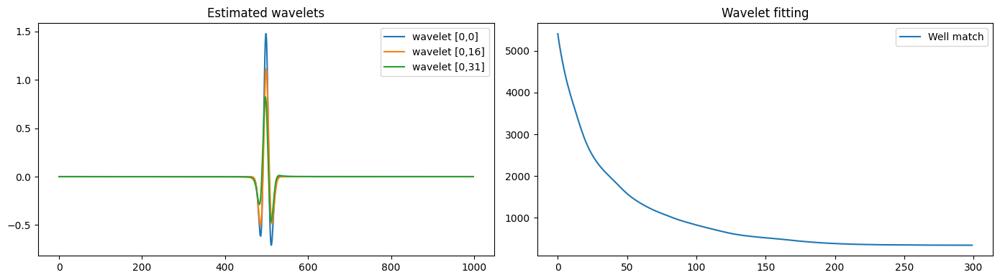

Estimated/saved wavelet difference RMSE: 9.203116860589944e-06


In [10]:
plt.figure(figsize=(14, 4))
plt.subplot(121)
for j in sorted(set([0, wavelet_mat.shape[1] // 2, wavelet_mat.shape[1] - 1])):
    plt.plot(wavelet_mat[0, j].cpu(), label=f"wavelet [0,{j}]")
plt.title("Estimated wavelets")
plt.legend()
plt.subplot(122)
plt.plot(norm_dic["match"], label="Well match")
plt.title("Wavelet fitting")
plt.legend()
plt.tight_layout()
plt.show()

reference_wavelet_path = data_dir / "estimated_wavelet_mat.npy"
if reference_wavelet_path.is_file():
    reference_wavelet = torch.from_numpy(np.load(reference_wavelet_path, allow_pickle=False)).float()
    if reference_wavelet.shape == wavelet_mat.shape:
        wavelet_difference = float((wavelet_mat.cpu() - reference_wavelet).square().mean().sqrt())
        print("Estimated/saved wavelet difference RMSE:", wavelet_difference)


## 8. Forward Modeling at Well Locations


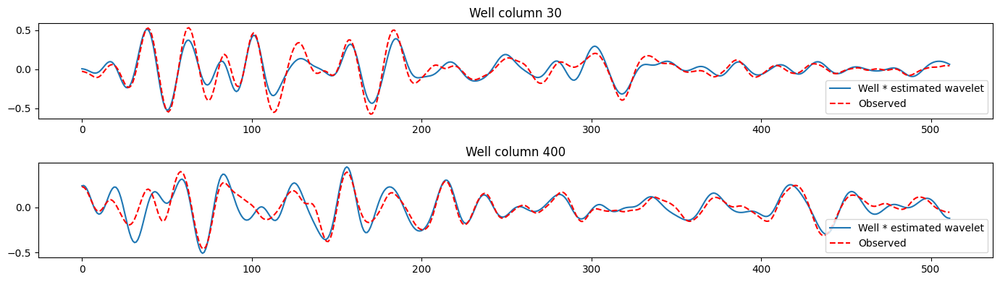

In [11]:
with torch.no_grad():
    seis_forward2 = wavelet_forward(
        wavelet_mat, data_well_slice.unsqueeze(0), window_new,
        seis_min, seis_max, imp_min, imp_max)
plt.figure(figsize=(14, max(3, 2 * len(dot))))
for j, trace in enumerate(dot):
    plt.subplot(len(dot), 1, j + 1)
    plt.plot(seis_forward2[0, 0, trace].cpu(), label="Well * estimated wavelet")
    plt.plot(cond_image[0, 0, trace].cpu(), "r--", label="Observed")
    plt.title(f"Well column {trace}")
    plt.legend()
plt.tight_layout()
plt.show()


## 9. Denoising and Data Fitting


In [12]:
def denoise(begin_step, image, num_steps, scheduler, cond_image, well_image,
            eta=1, scale=(1, 1), generator=None):
    # Keep the original interface; this method uses num_steps=1 per round with both conditioning networks.
    with torch.no_grad():
        steps = max(int(begin_step), 0)
        timesteps = (np.linspace(steps, 0, min(num_steps, round(steps))).round().astype(np.int64)
                     if steps != 0 else np.array([0]))
        scheduler.set_timesteps(timesteps=timesteps)
        for t in scheduler.timesteps:
            one = torch.ones((image.shape[0], 1, 1, 1), device=image.device, dtype=image.dtype)
            down_samples, mid_sample = controlnet(
                image, t, encoder_hidden_states=None,
                controlnet_cond=[cond_image, well_image],
                conditioning_scale=[one * scale[0], one * scale[1]],
                guess_mode=False, return_dict=False)
            model_output = unet(
                image, t, None,
                down_block_additional_residuals=down_samples,
                mid_block_additional_residual=mid_sample).sample
            image, image_pred_ori = scheduler.step(
                model_output, t, image, use_clipped_model_output=True,
                generator=generator, eta=eta, return_dict=False)
    return image, image_pred_ori, timesteps


In [13]:
def data_fitting(image_dif, image_denoise, net, opti_old, num_iterations, lr,
                 forward_fns, scale, wavelet_mat):
    image_init = image_denoise.clone().detach()
    net.train()

    # Keep parameters across rounds, recreate the optimizer each round, and do not carry Adam moments between rounds.
    for param_group in opti_old.param_groups:
        param_group["lr"] = float(lr)
    opti = type(opti_old)(opti_old.param_groups, **opti_old.defaults)

    norm_dics = defaultdict(list)
    for _ in range(num_iterations):
        image = image_init + net(image_dif).reshape_as(image_init)
        opti.zero_grad()
        values = {
            "forward_wavelet": forward_fns["forward_wavelet"](image=image, wavelet_mat=wavelet_mat),
            "initial": forward_fns["initial"](image=image),
            "data_keep": torch.linalg.norm(image - image_init) ** 2,
        }
        norm = sum(scale[key] * value for key, value in values.items())
        norm.backward()
        opti.step()
        for key, value in values.items():
            norm_dics[key].append(float(value.detach()))

    with torch.no_grad():
        net.eval()
        image_fit = (image_init + net(image_dif).reshape_as(image_init)).clamp(-1, 1)
    return image_fit.detach(), norm_dics


## 10. Inversion Parameters


In [14]:
num_runs = 1
if num_runs < 1:
    raise ValueError("num_runs must be at least 1.")
seed_start = 42
plot_seed = seed_start
epochs = 50
begin_ratio = 0.9
N_rev = 1  # Reverse-denoising steps per round.
num_iterations = 10
skip_fitting_rounds = 1
eta = 1
noise_floor = 1
plot_interval = max(1, int(epochs * begin_ratio) // 5)


## 11. Inversion Process


  0%|          | 0/45 [00:00<?, ?it/s]

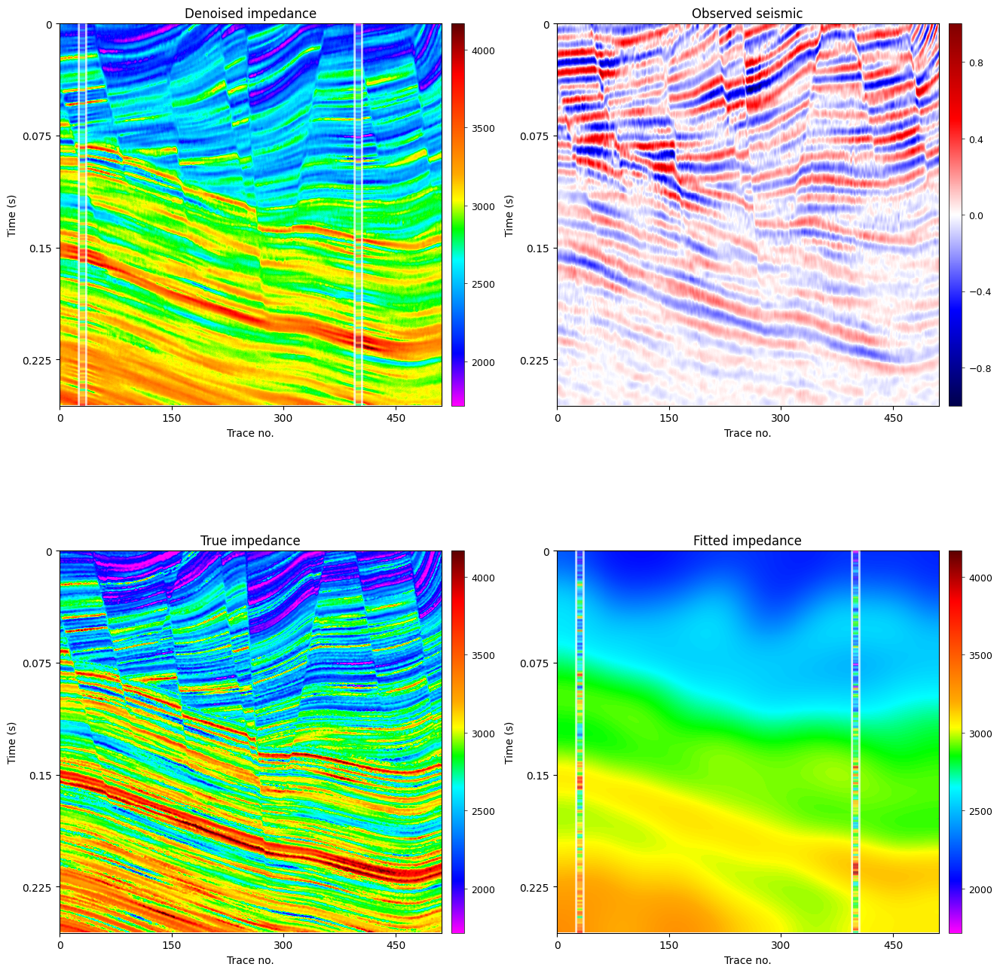

/tmp/ipykernel_898880/863951376.py:106: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


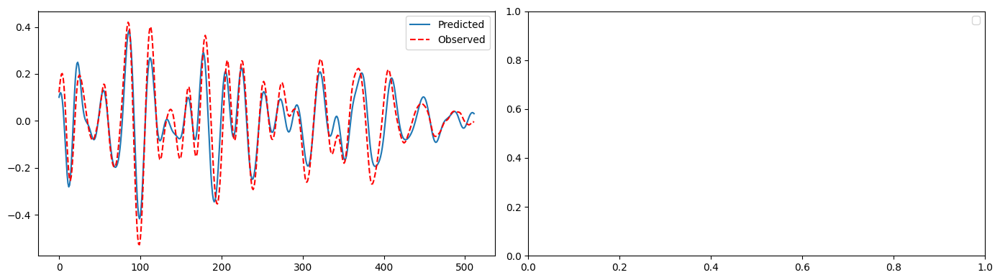

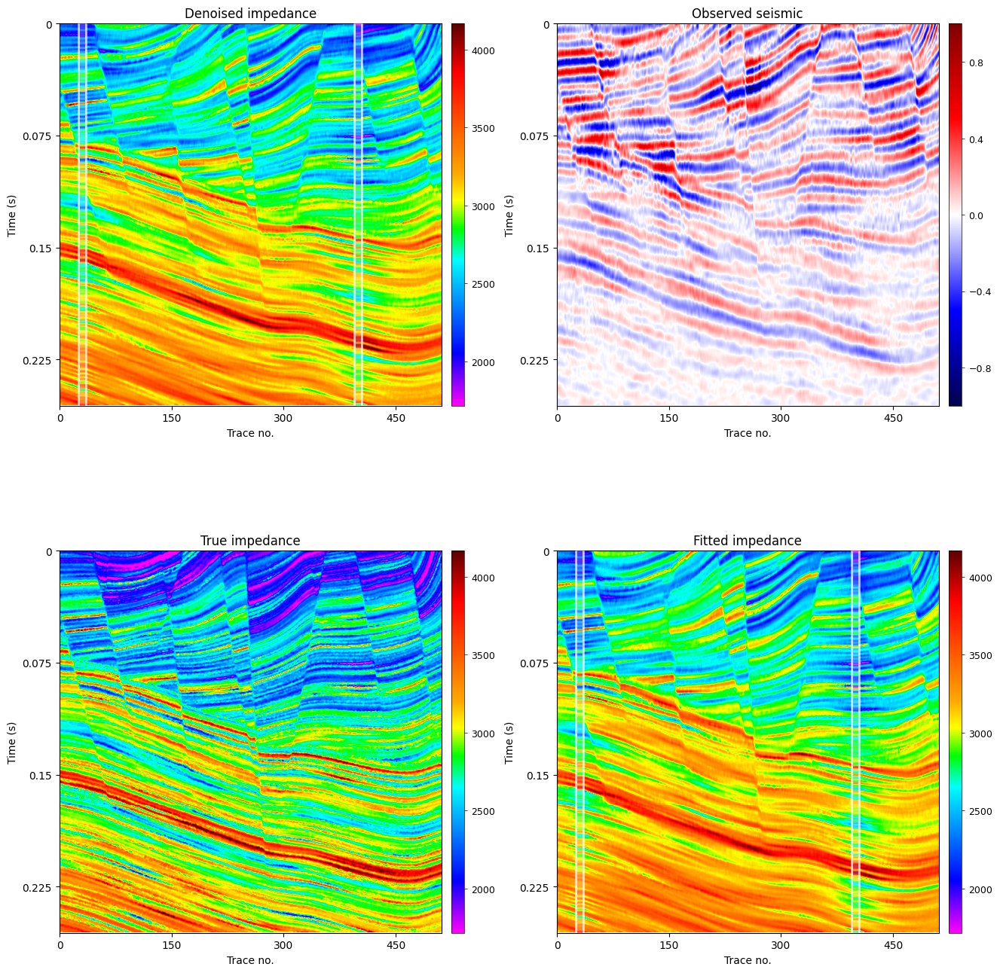

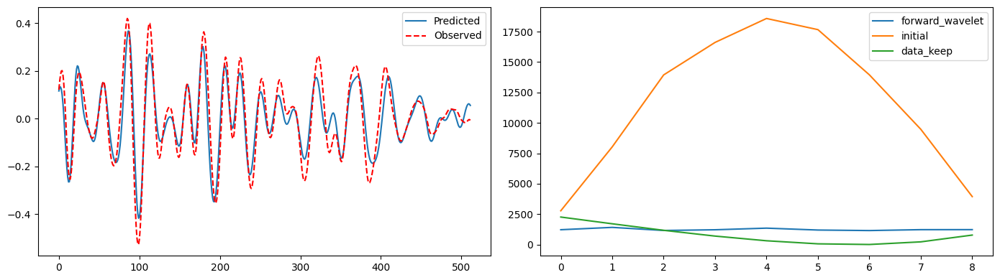

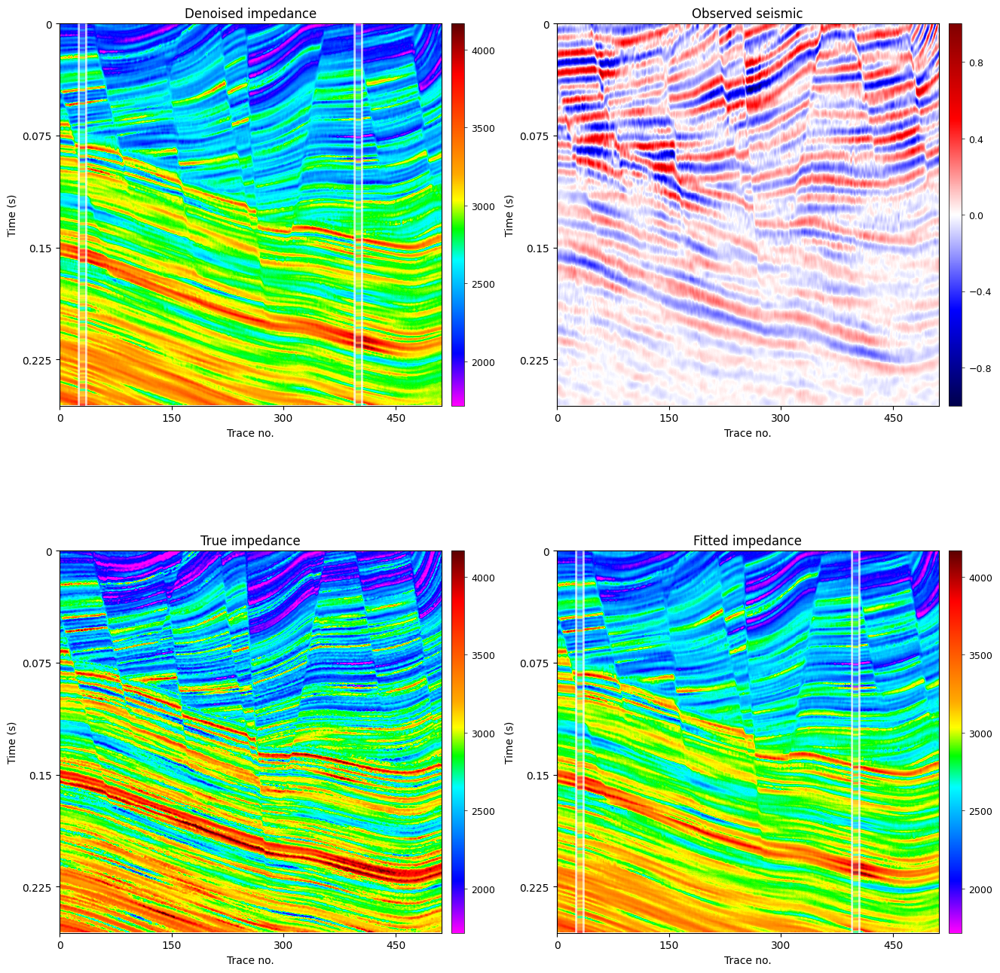

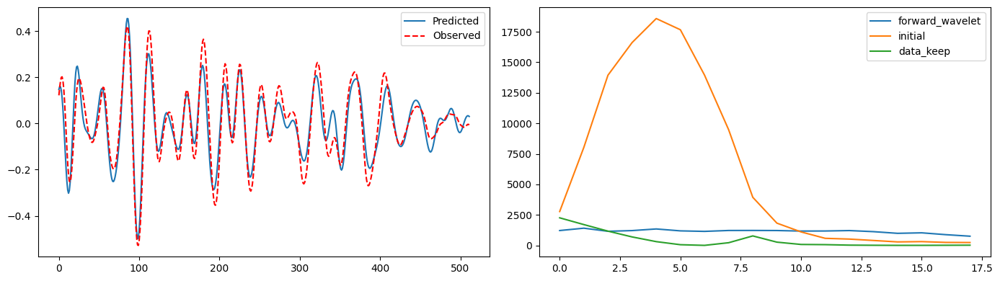

...

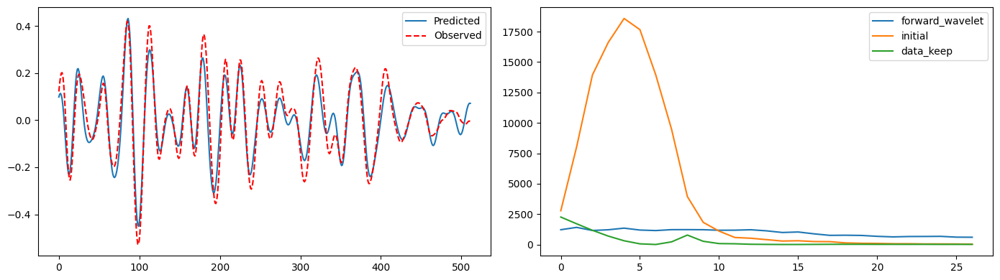

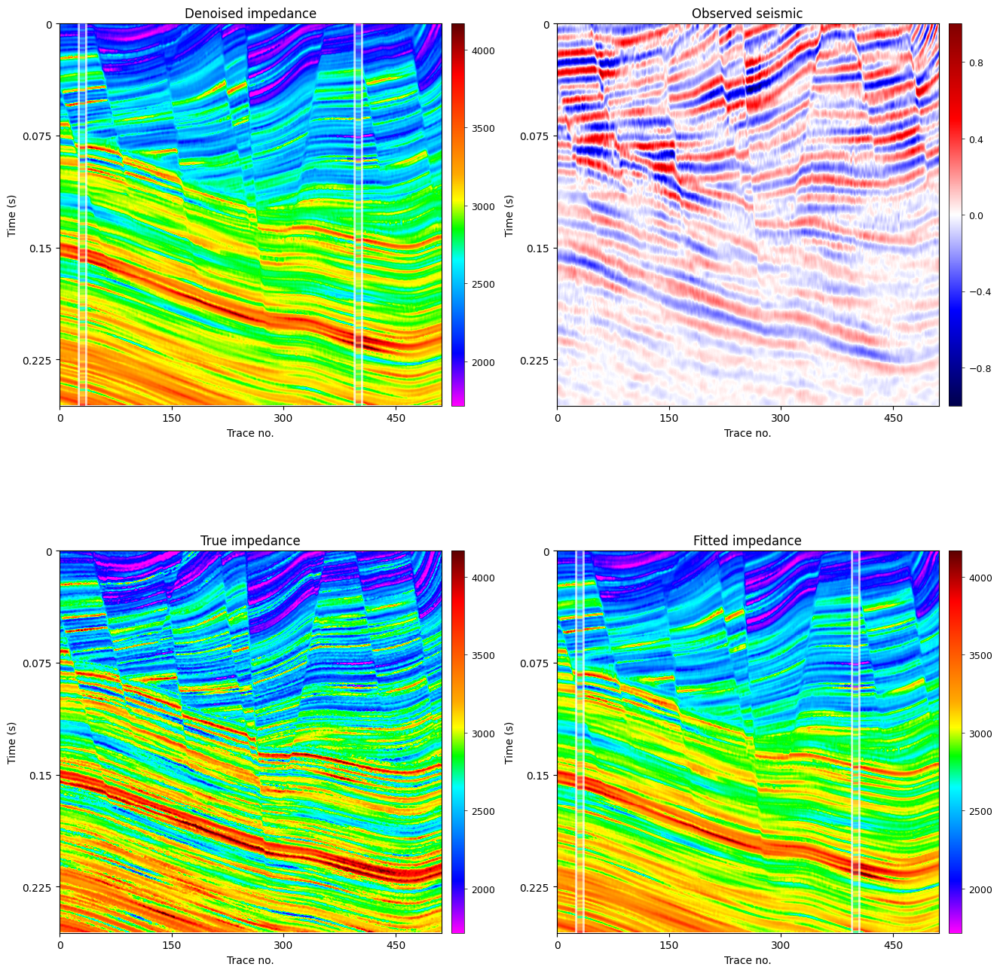

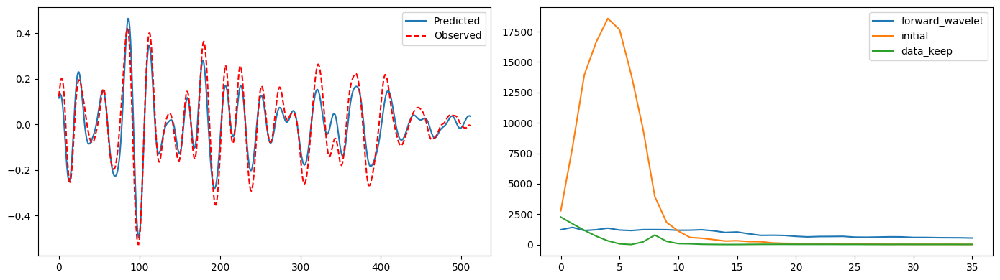

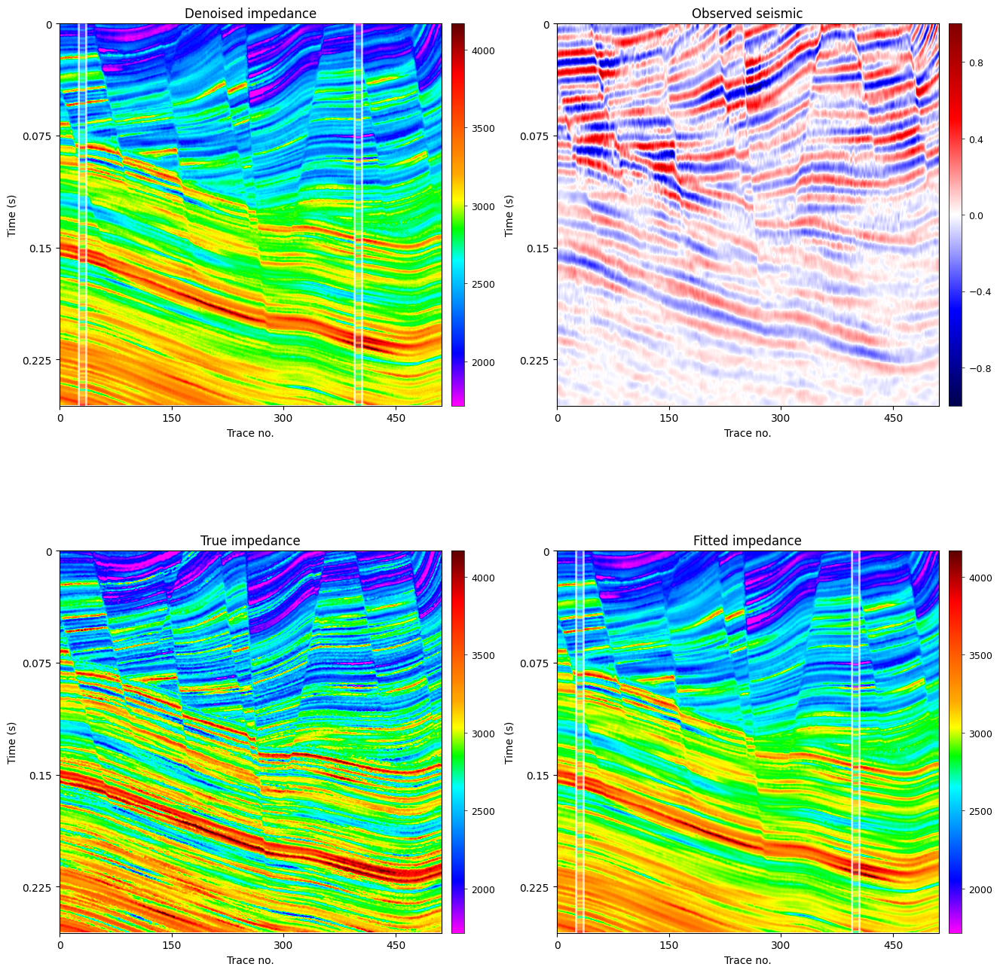

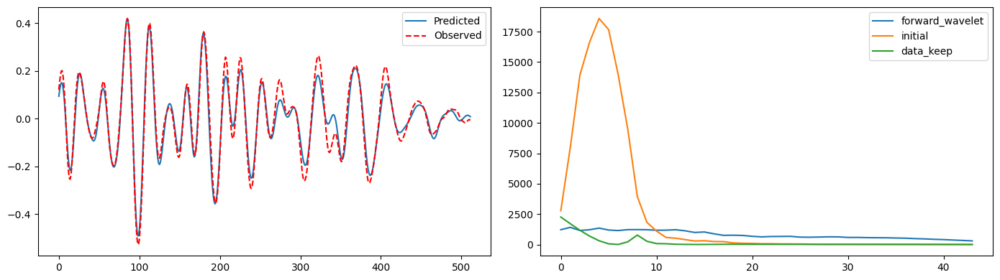

Seed: 42 | Metrics: {'RMSE': 189.85281372070312, 'PSNR': 25.06634542550958, 'SSIM': 0.6016285419464111, 'MAE': 142.417724609375, 'CorrCoef': 0.8953422009498595}


In [15]:
results = []
run_records = []
for iter in range(num_runs):
    seed = seed_start + iter
    torch.manual_seed(seed)
    if device.type == "cuda":
        torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    generator = torch.Generator(device=device).manual_seed(seed)

    # Preserve the original draw before the initial noise to keep the subsequent random sequence unchanged.
    image = randn_tensor(image_shape, generator=generator, device=device, dtype=torch.float32)
    image_fit = smoothed_norm.clone()
    image_denoise = smoothed_norm.clone()
    image_fit_noise = randn_tensor(image_shape, generator=generator, device=device, dtype=torch.float32)

    step_ratio = scheduler.config.num_train_timesteps // epochs
    timesteps2 = (np.arange(epochs) * step_ratio).round()[::-1].copy().astype(np.int64)
    scheduler2.set_timesteps(timesteps=timesteps2)
    begin_epoch = int(epochs * begin_ratio)
    ts = timesteps2[epochs - begin_epoch:]
    image_fit_noise = scheduler2.add_noise(image_fit, image_fit_noise, torch.tensor(int(ts[0])))
    # The original program also draws well noise; preserve this draw because it affects subsequent inversion noise.
    _ = randn_tensor(image_shape, generator=generator, device=device, dtype=torch.float32)

    lr_scheduler = np.linspace(0.0001, 0.001, begin_epoch)
    forward_wavelet_scheduler = np.linspace(0.2, 0.2, begin_epoch)
    initial_scheduler = np.linspace(1.0, 1.0, begin_epoch)
    datakeep_scheduler = np.linspace(2.0, 2.0, begin_epoch)
    scale_scheduler_well = np.linspace(4.0, 0.2, begin_epoch)
    scale_scheduler_seis = np.linspace(1.0, 1.0, begin_epoch)

    initial_func = partial(initial_fn, initial_image=smoothed_norm, background_filter=background_filter)
    forward_wavelet_func = partial(
        forward_wavelet_fn, cond_image=cond_image.detach(), window=window_new,
        imp_min=imp_min, imp_max=imp_max, seis_min=seis_min, seis_max=seis_max)

    config = {
        "encoding": {"otype": "HashGrid", "n_levels": 16, "n_features_per_level": 2,
                     "log2_hashmap_size": 16, "base_resolution": 500, "per_level_scale": 1.03},
        "mlp": {"Depth": 2, "Width": 64, "enc": "hash"},
    }
    coords = create_coords(seis.shape[-2:]).to(device)
    net = create_model(config, device)
    image4upgrade = coords
    opti = torch.optim.Adam(list(net.parameters()), lr=lr_scheduler[0])

    norm_dics = defaultdict(list)
    started = time.perf_counter()
    for i, epoch in tqdm(enumerate(range(begin_epoch, 0, -1)), total=begin_epoch):
        timestep = int(timesteps2[epochs - epoch])
        if i >= 1:
            if i >= skip_fitting_rounds:
                image_fit, norm_dic = data_fitting(
                    image4upgrade, image_denoise, net=net, opti_old=opti,
                    num_iterations=num_iterations, lr=lr_scheduler[i],
                    forward_fns={"forward_wavelet": forward_wavelet_func, "initial": initial_func},
                    scale={"forward_wavelet": forward_wavelet_scheduler[i],
                           "initial": initial_scheduler[i], "data_keep": datakeep_scheduler[i]},
                    wavelet_mat=wavelet_mat)
                image_fit = image_fit.clone().detach()
                for key, value in norm_dic.items():
                    norm_dics[key].extend(value[-1:])
            else:
                image_fit = image_denoise.detach()
            image_fit_noise = scheduler2.add_noise(
                image_fit, randn_tensor(image_shape, generator=generator, device=device, dtype=torch.float32),
                torch.tensor(max(timestep, noise_floor)))

        image_denoise, image_pred_ori, _ = denoise(
            timestep, image_fit_noise, N_rev, scheduler,
            cond_image=cond_image_denoise, well_image=well_image2, eta=eta,
            scale=[scale_scheduler_seis[i], min(1.0, scale_scheduler_well[i])], generator=generator)
        image_denoise = image_denoise.clamp(-1, 1)

        if seed == plot_seed and plot_interval and (i % plot_interval == 0 or i == begin_epoch - 1):
            with torch.no_grad():
                model_output_denorm = (image_denoise * 0.5 + 0.5) * (imp_max - imp_min) + imp_min
                seis_forward = wavelet_forward(
                    wavelet_mat, image_denoise, window_new, seis_min, seis_max, imp_min, imp_max)
            plt.figure(figsize=section_figure_size(raw_image.shape[-2:], rows=2, cols=2, dataset=plot_options["dataset"]))
            for panel, array, title, colors, lo, hi in [
                (1, model_output_denorm[0, 0], "Denoised impedance", cmap, plot_min, plot_max),
                (2, cond_image[0, 0], "Observed seismic", cmap2, -1, 1),
                (3, raw_image_denorm[0], "True impedance", cmap, plot_min, plot_max),
                (4, (image_fit[0, 0] * 0.5 + 0.5) * (imp_max - imp_min) + imp_min,
                 "Fitted impedance", cmap, plot_min, plot_max)]:
                plt.subplot(2, 2, panel)
                plt.imshow(array.cpu().T, cmap=colors, vmin=lo, vmax=hi, aspect=aspect)
                paper_section(plt.gca(), plt.gci(), impedance=colors is cmap,
                              show_wells=title != "True impedance", **plot_options)
                plt.title(title)
                add_colorbar(plt.gcf(), plt.gci(), plt.gca())
            plt.tight_layout()
            plt.show()

            plt.figure(figsize=(14, 4))
            plt.subplot(121)
            trace = min(200, seis.shape[-2] - 1)
            plt.plot(seis_forward[0, 0, trace].cpu(), label="Predicted")
            plt.plot(cond_image[0, 0, trace].cpu(), "r--", label="Observed")
            plt.legend()
            plt.subplot(122)
            for key, value in norm_dics.items():
                plt.plot(value, label=key)
            plt.legend()
            plt.tight_layout()
            plt.show()

    image = (image_denoise * 0.5 + 0.5).clamp(0, 1)
    results.append(image.detach().cpu())
    physical = image.cpu()[0, 0] * (imp_max - imp_min) + imp_min
    metrics = calc_metrics(physical, raw_image_denorm[0].cpu(), metric_data_range)
    record = dict(seed=seed, metrics=metrics, norm_dics=dict(norm_dics),
                  elapsed_seconds=time.perf_counter() - started)
    run_records.append(record)
    np.save(output_dir / f"seed_{seed}.npy", physical.numpy())
    (output_dir / f"seed_{seed}.json").write_text(
        json.dumps(record, indent=2) + "\n", encoding="utf-8")
    print("Seed:", seed, "| Metrics:", metrics)
    del image4upgrade, net, opti


## 12. Ensemble Evaluation, Plotting, and Saving


,seed,retained,RMSE,PSNR,SSIM,MAE,CorrCoef
0,42,True,189.852814,25.066345,0.601629,142.417725,0.895342


Mean model: {'RMSE': 189.85281372070312, 'PSNR': 25.06634542550958, 'SSIM': 0.6016285419464111, 'MAE': 142.417724609375, 'CorrCoef': 0.8953422009498595}
Mean individual-run metrics (retained): {'RMSE': 189.85281372070312, 'PSNR': 25.06634542550958, 'SSIM': 0.6016285419464111, 'MAE': 142.417724609375, 'CorrCoef': 0.8953422009498595}


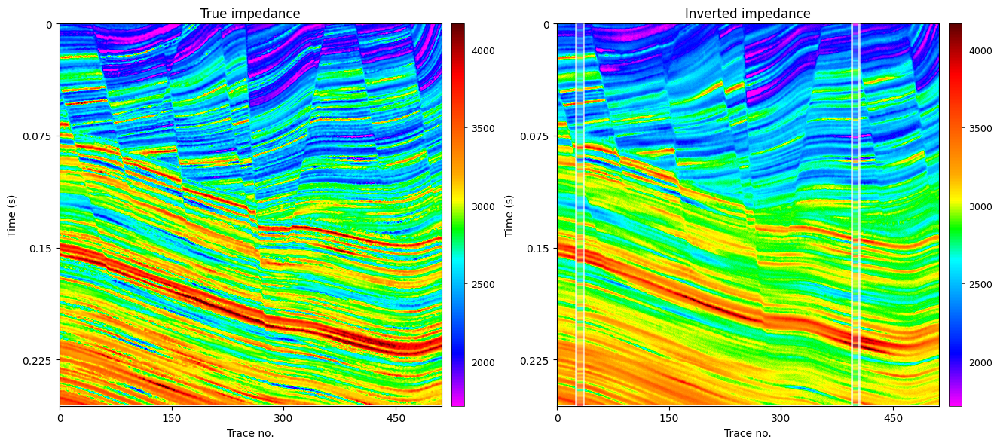

In [16]:
filt_results = torch.cat(results, dim=0) * (imp_max - imp_min) + imp_min
retained = torch.ones(len(results), dtype=torch.bool)
if False and len(results) > 1:
    spatial_std = filt_results.flatten(1).std(dim=1)
    retained = (spatial_std > spatial_std.mean() * 0.8) & (spatial_std < spatial_std.mean() * 1.2)
    if not retained.any():
        raise RuntimeError("The spatial-standard-deviation filter retained no models.")
selected = filt_results[retained]
image = selected.mean(0, keepdim=True)
image_std = selected.std(0, correction=1) if len(selected) > 1 else torch.zeros_like(selected[0])
evaluation = calc_metrics(image[0, 0], raw_image_denorm[0].cpu(), metric_data_range)
display(pd.DataFrame([dict(seed=r["seed"], retained=bool(keep), **r["metrics"])
                      for r, keep in zip(run_records, retained)]))
print("Mean model:", evaluation)
independent_mean = {
    key: float(np.mean([r["metrics"][key] for r, keep in zip(run_records, retained) if keep]))
    for key in evaluation
}
print("Mean individual-run metrics (retained):", independent_mean)
summary = dict(ensemble=evaluation, mean_independent_retained=independent_mean, seeds=[r["seed"] for r in run_records],
               retained_seeds=[r["seed"] for r, keep in zip(run_records, retained) if keep])
(output_dir / "metrics_summary.json").write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")
np.save(output_dir / "ensemble_mean.npy", image[0, 0].numpy())
np.save(output_dir / "ensemble_std.npy", image_std[0].numpy())
pd.DataFrame([dict(seed=r["seed"], retained=bool(keep), **r["metrics"])
              for r, keep in zip(run_records, retained)]).to_csv(
    output_dir / "metrics_per_run.csv", index=False)

plt.figure(figsize=section_figure_size(raw_image.shape[-2:], dataset=plot_options["dataset"]))
plt.subplot(121)
plt.imshow(raw_image_denorm[0].cpu().T, cmap=cmap, vmin=plot_min, vmax=plot_max, aspect=aspect)
paper_section(plt.gca(), plt.gci(), impedance=True,
              show_wells=False, **plot_options)
plt.title("True impedance")
add_colorbar(plt.gcf(), plt.gci(), plt.gca())
plt.subplot(122)
plt.imshow(image[0, 0].T, cmap=cmap, vmin=plot_min, vmax=plot_max, aspect=aspect)
paper_section(plt.gca(), plt.gci(), impedance=True,
              show_wells=True, **plot_options)
plt.title("Inverted impedance" if num_runs == 1 else "Mean inversion")
add_colorbar(plt.gcf(), plt.gci(), plt.gca())
plt.tight_layout()
plt.savefig(output_dir / "inversion_result.png", dpi=160, bbox_inches="tight")
plt.show()
